### 07 · Emulador: PCs simuladas (PVAR) → f (XGB) → ruido (TAR) → Hs
Tres generadores de `var_h1` (02A), mismos modelos de f (04) y de ruido (05):
- `h1`: choques gaussianos · `h1b`: bootstrap de choques sueltos · `h1bb24`: bootstrap por bloques de 6 días.

Validación en **bloques de 41 años** (la longitud del observado, 1985–2025), frente al observado y al **hindcast** (f histórica + mismo ruido, del 05). La diferencia de cada generador con el hindcast mide **solo el generador**; la del hindcast con el observado, **solo el ruido**.

Salidas: `outputs/emulador/{generador}/sim_XXX.parquet` (Hs y f horarias).

In [1]:
import os, glob, json, pickle, time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from scipy.signal import find_peaks
from scipy.stats import genextreme

from utils.pit.piece_wise_marginal import from_normal

os.makedirs("figuras", exist_ok=True)
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

#### Configuración

In [2]:
point = "p102"
GENERADORES = ["h1", "h1b", "h1bb24"]
COLOR = {"h1": GRIS, "h1b": AZUL, "h1bb24": NARANJA}
N_SIMS = 20                                   # por generador (100 para los resultados finales; las ya hechas se saltan)
PERIODO = ("1941", "2022")                     # 2 bloques de 41 años por simulación: 1941–1981 y 1982–2022
BLOQUE = 41
OUT = "outputs/emulador"

#### Modelos: XGB (04), ruido TAR (05) y transformación PIT

In [3]:
xgb = XGBRegressor()
xgb.load_model(f"outputs/xgb_{point}/xgb_final.json")
meta = json.load(open(f"outputs/xgb_{point}/xgb_features.json"))
lags = meta["lags_h"]

ruido = pickle.load(open(f"outputs/ruido/ruido_tar_{point}.pkl", "rb"))
P, U_REG, coef, innov, bordes, pools = (ruido[k] for k in ["P", "U_REG", "coef", "innov", "bordes", "pools"])

tr_ = pickle.load(open(f"outputs/marginal/transformacion_{point}.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

def f_desde_pcs(pcs):
    """PCs 6-horarias (30 presión + 10 gradiente reconstruido) → f horaria, igual que en el 04."""
    X = pd.concat({f"l{l}": pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs.index)
    X.columns = [f"{c}_l{l[1:]}" for l, c in X.columns]
    X = X.dropna()[meta["columns"]]
    return pd.Series(xgb.predict(X), index=X.index).resample("h").interpolate()

def ruido_tar(f, rng, burn=24 * 30):
    g = (f.values >= U_REG).astype(int)
    g = np.r_[np.full(burn, g[0]), g]
    e = np.where(g == 1, rng.choice(innov[1], len(g)), rng.choice(innov[0], len(g)))
    c0 = np.array([coef[0][0], coef[1][0]])
    a = np.stack([coef[0][1:], coef[1][1:]])
    x = np.zeros(len(g) + P)
    for t in range(len(g)):
        x[t + P] = c0[g[t]] + a[g[t]] @ x[t:t + P][::-1] + e[t]
    return x[P + burn:]

def mapear(u, f):
    dec = np.digitize(f.values, bordes)
    mes = f.index.month
    r = np.empty(len(u))
    for (m, d), pool in pools.items():
        sel = (mes == m) & (dec == d)
        if sel.sum():
            r[sel] = np.quantile(pool, (pd.Series(u[sel]).rank().values - 0.5) / sel.sum())
    return r

def hs_desde_f(f, rng):
    return hs_desde_z(f + mapear(ruido_tar(f, rng), f))

In [4]:
#### Comprobación: las PCs históricas por esta misma cadena dan la f del 04 (test 2016–2025)
pcs_hist = pd.read_csv("outputs/pca/pcs_msl_30_6h.csv", index_col=0, parse_dates=True).join(
           pd.read_csv("outputs/grad_rec/pcs_grad_rec_6h.csv", index_col=0, parse_dates=True))
f_hist = f_desde_pcs(pcs_hist).loc["1941":"2025"]
f_04 = pd.read_csv(f"outputs/xgb_{point}/residuos_horarios.csv", index_col=0, parse_dates=True)["f"]
t = f_04.loc["2016":"2025"].index.intersection(f_hist.index)
print(f"corr f (aquí) vs f (04) en test: {f_hist.loc[t].corr(f_04.loc[t]):.4f}  (≈ 1)")

corr f (aquí) vs f (04) en test: 1.0000  (≈ 1)


#### Emulador: Hs horaria de cada simulación (las que existen se saltan)

In [5]:
for g in GENERADORES:
    carpeta = f"{OUT}/{g}"
    os.makedirs(carpeta, exist_ok=True)
    ficheros = sorted(glob.glob(f"outputs/var_6h/simulaciones_{g}/sim_*.parquet"))[:N_SIMS]
    for i, fic in enumerate(ficheros):
        f_out = f"{carpeta}/{os.path.basename(fic)}"
        if os.path.exists(f_out):
            continue
        t0 = time.time()
        fg = os.path.join(f"outputs/grad_rec/simulaciones_{g}", os.path.basename(fic).replace("sim_", "grec_"))
        pcs = pd.read_parquet(fic).astype("float64").join(pd.read_parquet(fg).astype("float64"))
        f_h = f_desde_pcs(pcs).loc[PERIODO[0]:PERIODO[1]]
        hs = hs_desde_f(f_h, np.random.default_rng(i))
        pd.DataFrame({"VHM0": hs, "f": f_h}).astype("float32").to_parquet(f_out)
        print(f"{g} sim {i:03d} ({time.time() - t0:.0f} s)")

#### Validación en bloques de 41 años

In [6]:
hs_obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"].asfreq("h")
U90, U99 = hs_obs.quantile(0.90), hs_obs.quantile(0.99)
print(f"U90 {U90:.2f} m | U99 {U99:.2f} m")

def est4(ix):
    return np.select([ix.month.isin([12, 1, 2]), ix.month.isin([3, 4, 5]), ix.month.isin([6, 7, 8])],
                     ["invierno", "primavera", "verano"], "otoño")

def picos_temporal(s):
    return s.index[find_peaks(s.fillna(0).values, height=U99, distance=72)[0]]

def duraciones(s, u):
    d = np.diff(np.r_[0, (s.values > u).astype(int), 0])
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def metricas(s):
    """Estadísticos de un bloque de Hs horaria (observado, una realización del hindcast o un bloque del emulador)."""
    n_dec = s.dropna().index.year.nunique() / 10
    pk = picos_temporal(s)
    am = s.groupby(s.index.year).max().dropna()
    c, loc, sc = genextreme.fit(am.values)
    return {"q99": s.quantile(0.99), "q99.9": s.quantile(0.999),
            "temporales / década": len(pk) / n_dec,
            **{f"  {e}": (est4(pk) == e).sum() / n_dec for e in ["invierno", "primavera", "verano", "otoño"]},
            "duración > U99 [h]": duraciones(s, U99).mean(), "duración > U90 [h]": duraciones(s, U90).mean(),
            "máx. anual media": am.mean(), "máx. anual σ": am.std(),
            "GEV ξ": -c, "GEV σ": sc, **{f"Hs{T}": genextreme.isf(1 / T, c, loc, sc) for T in [2, 10, 50, 100]}}

def bloques(s):
    a0, a1 = int(PERIODO[0]), int(PERIODO[1])
    return [s.loc[str(a):str(a + BLOQUE - 1)] for a in range(a0, a1 - BLOQUE + 2, BLOQUE)]

#### Observado, hindcast (cada realización = un bloque de 41 años) y generadores (2 bloques por simulación)
m_obs = pd.Series(metricas(hs_obs))
hind = pd.read_pickle(f"outputs/ruido/hs_hindcast_{point}.pkl").astype("float64")
m_sim = {"hindcast": pd.DataFrame([metricas(hind[c].where(hs_obs.reindex(hind.index).notna())) for c in hind.columns])}
am_sim = {"hindcast": [hind[c].groupby(hind.index.year).max().values for c in hind.columns]}
for g in GENERADORES:
    filas, ams = [], []
    for fic in sorted(glob.glob(f"{OUT}/{g}/sim_*.parquet")):
        hs = pd.read_parquet(fic)["VHM0"].astype("float64")
        for b in bloques(hs):
            filas.append(metricas(b))
            ams.append(b.groupby(b.index.year).max().values)
    m_sim[g], am_sim[g] = pd.DataFrame(filas), ams
    print(g, len(filas), "bloques")

U90 1.91 m | U99 3.73 m
h1 40 bloques
h1b 40 bloques
h1bb24 200 bloques


In [7]:
#### Tabla principal: mediana de los bloques / observado, y rango percentil del observado (≈ 50 ideal)
tabla = pd.DataFrame({"observado": m_obs})
for k, m in m_sim.items():
    tabla[f"{k} p50/obs"] = m.median() / m_obs
for k, m in m_sim.items():
    tabla[f"{k} rango obs"] = (m < m_obs).mean() * 100
tabla.round(2)

,observado,hindcast p50/obs,h1 p50/obs,h1b p50/obs,h1bb24 p50/obs,hindcast rango obs,h1 rango obs,h1b rango obs,h1bb24 rango obs
q99,3.73,1.01,0.98,0.99,1.01,0.0,87.5,80.0,21.5
q99.9,5.30,1.02,0.99,1.01,1.02,6.0,72.5,42.5,23.0
temporales / década,62.20,1.06,0.89,0.90,1.03,0.0,95.0,95.0,28.0
invierno,32.68,1.03,1.04,1.02,1.08,24.0,30.0,35.0,18.5
primavera,12.68,1.15,0.73,0.73,1.00,2.0,100.0,95.0,48.0
verano,0.73,1.17,1.00,1.33,1.00,30.0,32.5,22.5,37.0
otoño,16.10,1.08,0.67,0.77,0.94,18.0,100.0,100.0,71.0
duración > U99 [h],10.36,0.97,0.99,1.02,1.02,78.0,55.0,35.0,40.5
duración > U90 [h],16.72,0.98,0.95,0.95,0.99,88.0,97.5,100.0,63.5
máx. anual media,5.66,1.02,0.98,0.99,1.00,8.0,80.0,60.0,50.5


In [8]:
#### Solo el generador: f de las PCs simuladas frente a f de las PCs históricas (1941–2025)
def resumen_f(f):
    am = f.groupby(f.index.year).max()
    return {"q90": f.quantile(0.90), "q99": f.quantile(0.99), "q99.9": f.quantile(0.999),
            "máx. anual media": am.mean(), "máx. anual σ": am.std()}

r_hist = pd.Series(resumen_f(f_hist))
tabla_f = pd.DataFrame({"f histórica": r_hist})
for g in GENERADORES:
    rs = pd.DataFrame([resumen_f(pd.read_parquet(fic)["f"].astype("float64")) for fic in sorted(glob.glob(f"{OUT}/{g}/sim_*.parquet"))])
    tabla_f[f"{g} / hist"] = rs.median() / r_hist
tabla_f.round(3)

,f histórica,h1 / hist,h1b / hist,h1bb24 / hist
q90,1.041,0.907,0.906,0.970
q99,1.893,0.957,0.969,0.992
q99.9,2.474,0.977,1.008,0.998
máx. anual media,2.495,0.966,0.995,0.988
máx. anual σ,0.224,1.126,1.185,1.105


#### Figuras

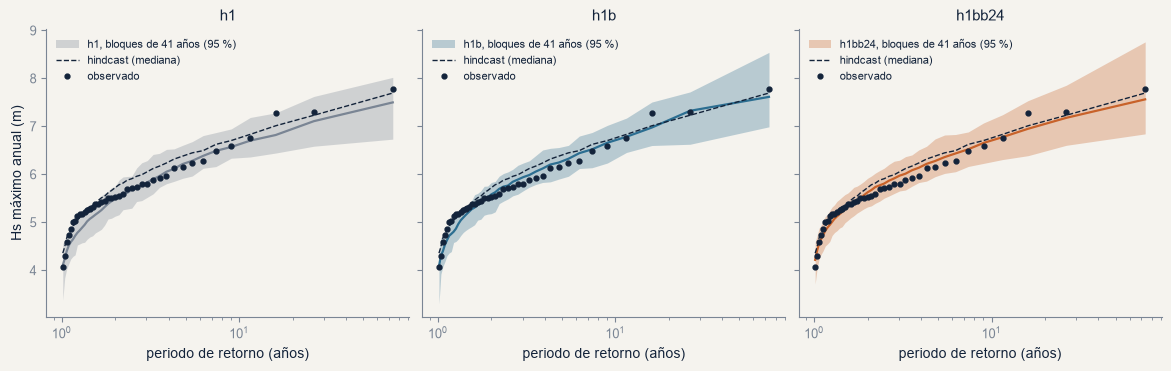

In [9]:
#### Periodos de retorno (Gringorten): banda 95 % de los bloques de cada generador, hindcast y observado
def gringorten(am):
    am = np.sort(np.asarray(am)); n = len(am)
    return 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12)), am

T_obs, x_obs = gringorten(hs_obs.groupby(hs_obs.index.year).max().dropna())
fig, axs = plt.subplots(1, len(GENERADORES), figsize=(11.6, 3.6), constrained_layout=True, sharey=True)
for ax, g in zip(axs, GENERADORES):
    ords = np.array([np.sort(a)[:BLOQUE] for a in am_sim[g] if len(a) >= BLOQUE]).T
    T_b = gringorten(np.arange(ords.shape[0]))[0]
    ax.fill_between(T_b, np.percentile(ords, 2.5, axis=1), np.percentile(ords, 97.5, axis=1), color=COLOR[g], alpha=0.3, lw=0,
                    label=f"{g}, bloques de 41 años (95 %)")
    ax.plot(T_b, np.median(ords, axis=1), color=COLOR[g], lw=1.6)
    hind_ord = np.array([np.sort(a) for a in am_sim["hindcast"]]).T
    ax.plot(gringorten(np.arange(hind_ord.shape[0]))[0], np.median(hind_ord, axis=1), color=TINTA, lw=1, ls="--", label="hindcast (mediana)")
    ax.plot(T_obs, x_obs, "o", color=TINTA, ms=3.5, label="observado")
    ax.set(xscale="log", xlabel="periodo de retorno (años)", title=g)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
axs[0].set_ylabel("Hs máximo anual (m)")
fig.savefig("figuras/emulador_gringorten.png", dpi=200)
plt.show()

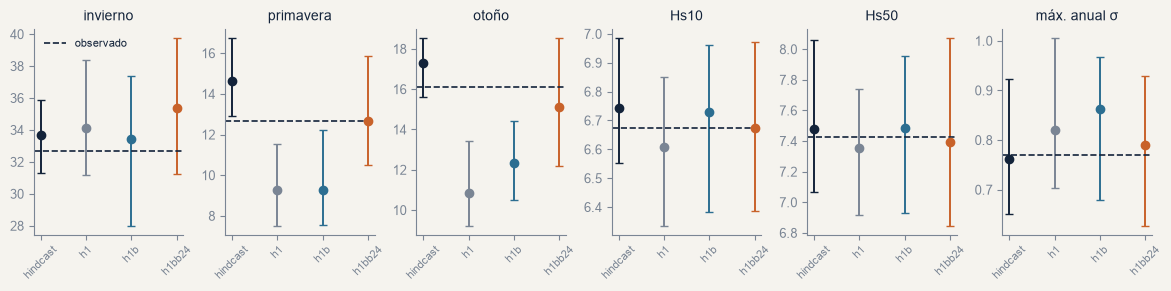

In [12]:
#### Temporales por estación y niveles de retorno: observado vs p5–p50–p95 de cada columna
claves = ["  invierno", "  primavera", "  otoño", "Hs10", "Hs50", "máx. anual σ"]
nombres = ["hindcast"] + GENERADORES
fig, axs = plt.subplots(1, len(claves), figsize=(11.6, 2.8), constrained_layout=True)
for ax, k in zip(axs, claves):
    for j, n in enumerate(nombres):
        v = m_sim[n][k]
        p5, p50, p95 = v.quantile([0.05, 0.5, 0.95])
        ax.errorbar(j, p50, yerr=[[p50 - p5], [p95 - p50]], fmt="o", color=COLOR.get(n, TINTA), capsize=3, lw=1.4)
    ax.axhline(m_obs[k], color=TINTA, lw=1.2, ls="--", label="observado")
    ax.set_xticks(range(len(nombres)), nombres, rotation=45, fontsize=8)
    ax.set_title(k.strip(), fontsize=10)
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig("figuras/emulador_metricas.png", dpi=200)
plt.show()